# Text similarity for information retrieval

Imagine you are conducting a study of municipal climate adaptation policies. You have collected hundreds of municipal policy documents and want to identify policies addressing waste management in the context of wildfires.

Research query: "Municipal policies for managing waste generated by wildfires"

We'll use eight fictional policy excerpts.

## Data preparation

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "policy_id": range(1, 9),
    "municipality": [
        "City A", "City B", "City C", "City D",
        "City E", "City F", "City G", "City H"
    ],
    "policy_text": [
        # 1. Directly relevant
        "The municipality will establish procedures for collecting, "
        "transporting, and disposing of waste generated by wildfires.",

        # 2. Semantically relevant, different vocabulary
        "Following major vegetation fires, local authorities will "
        "coordinate the removal of burned building materials, ash, "
        "and hazardous debris from affected residential areas.",

        # 3. Wildfire policy, but not waste management
        "The city will invest in wildfire prevention through vegetation "
        "management, firebreak construction, and early warning systems.",

        # 4. Waste management, but not wildfire
        "The municipal solid waste management plan establishes "
        "recycling programs, landfill operations, and household "
        "waste collection schedules.",

        # 5. Relevant, focuses on hazardous materials
        "After wildfire disasters, hazardous debris and contaminated "
        "ash must be safely collected and disposed of in approved facilities.",

        # 6. Disaster waste management, but not wildfire-specific
        "The emergency management department will coordinate debris "
        "removal and temporary waste storage following hurricanes "
        "and severe storms.",

        # 7. Wildfire impacts, but not waste management
        "The wildfire resilience strategy prioritizes evacuation "
        "planning, emergency shelters, and community education.",

        # 8. Shares keywords but has different focus
        "The wildfire waste management budget will be reviewed "
        "annually to assess administrative expenditures and staffing."
    ]
})

df

,policy_id,municipality,policy_text
0,1,City A,The municipality will establish procedures for...
1,2,City B,"Following major vegetation fires, local author..."
2,3,City C,The city will invest in wildfire prevention th...
3,4,City D,The municipal solid waste management plan esta...
4,5,City E,"After wildfire disasters, hazardous debris and..."
5,6,City F,The emergency management department will coord...
6,7,City G,The wildfire resilience strategy prioritizes e...
7,8,City H,The wildfire waste management budget will be r...


## Retrieve policies using TF-IDF

TF-IDF measures lexical similarity based on word overlap and relative word importance.

TF-IDF will favor passages sharing words such as "waste," "wildfires," and "management" with the query. Policy 2 may score relatively poorly despite being highly relevant because it uses different vocabulary.

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

query = "Municipal policies for managing waste generated by wildfires"

# Convert policy documents into TF-IDF vectors
vectorizer = TfidfVectorizer(
    stop_words="english"
)

tfidf_matrix = vectorizer.fit_transform(df["policy_text"])

# Convert query into the same vector space
query_vector = vectorizer.transform([query])

# Calculate similarity between query and each policy
tfidf_scores = cosine_similarity(
    query_vector,
    tfidf_matrix
).flatten()

# Add scores
df["tfidf_score"] = tfidf_scores

# Rank policies
df[["policy_id", "policy_text", "tfidf_score"]].sort_values(
    "tfidf_score",
    ascending=False
)

,policy_id,policy_text,tfidf_score
0,1,The municipality will establish procedures for...,0.449283
3,4,The municipal solid waste management plan esta...,0.271175
7,8,The wildfire waste management budget will be r...,0.076094
5,6,The emergency management department will coord...,0.068465
1,2,"Following major vegetation fires, local author...",0.000000
2,3,The city will invest in wildfire prevention th...,0.000000
4,5,"After wildfire disasters, hazardous debris and...",0.000000
6,7,The wildfire resilience strategy prioritizes e...,0.000000


## Retrieve policies using sentence embeddings

Sentence embeddings can capture relationships between different expressions of similar concepts.

For example, "waste generated by wildfires" and "ash and burned building debris" are conceptually related, even though they share relatively few words.

In [3]:
from sentence_transformers import SentenceTransformer

# Load model
model = SentenceTransformer("all-MiniLM-L6-v2")

# Convert policy documents into embeddings
policy_embeddings = model.encode(df["policy_text"].tolist())

# Convert query into embedding
query_embedding = model.encode([query])

# Calculate cosine similarity
embedding_scores = cosine_similarity(
    query_embedding,
    policy_embeddings
).flatten()

df["embedding_score"] = embedding_scores

# Rank policies
df[["policy_id", "policy_text", "embedding_score"]].sort_values(
    "embedding_score",
    ascending=False
)

W1106 15:32:49.358000 43893 .venv/lib/python3.14/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,policy_id,policy_text,embedding_score
0,1,The municipality will establish procedures for...,0.785421
7,8,The wildfire waste management budget will be r...,0.652933
4,5,"After wildfire disasters, hazardous debris and...",0.632822
1,2,"Following major vegetation fires, local author...",0.598896
2,3,The city will invest in wildfire prevention th...,0.581227
3,4,The municipal solid waste management plan esta...,0.555542
6,7,The wildfire resilience strategy prioritizes e...,0.499465
5,6,The emergency management department will coord...,0.494222


## Compare the rankings
For information retrieval, the ranking of documents is often more important than the similarity scores themselves.

In [4]:
# Calculate ranking for each method
df["tfidf_rank"] = df["tfidf_score"].rank(
    ascending=False, method="min"
).astype(int)

df["embedding_rank"] = df["embedding_score"].rank(
    ascending=False, method="min"
).astype(int)

# Compare
comparison = df[[
    "policy_id",
    "tfidf_score",
    "tfidf_rank",
    "embedding_score",
    "embedding_rank"
]]

comparison.sort_values("tfidf_rank")

,policy_id,tfidf_score,tfidf_rank,embedding_score,embedding_rank
0,1,0.449283,1,0.785421,1
3,4,0.271175,2,0.555542,6
7,8,0.076094,3,0.652933,2
5,6,0.068465,4,0.494222,8
1,2,0.000000,5,0.598896,4
2,3,0.000000,5,0.581227,5
4,5,0.000000,5,0.632822,3
6,7,0.000000,5,0.499465,7


Text(0, 0.5, 'Semantic Similarity')

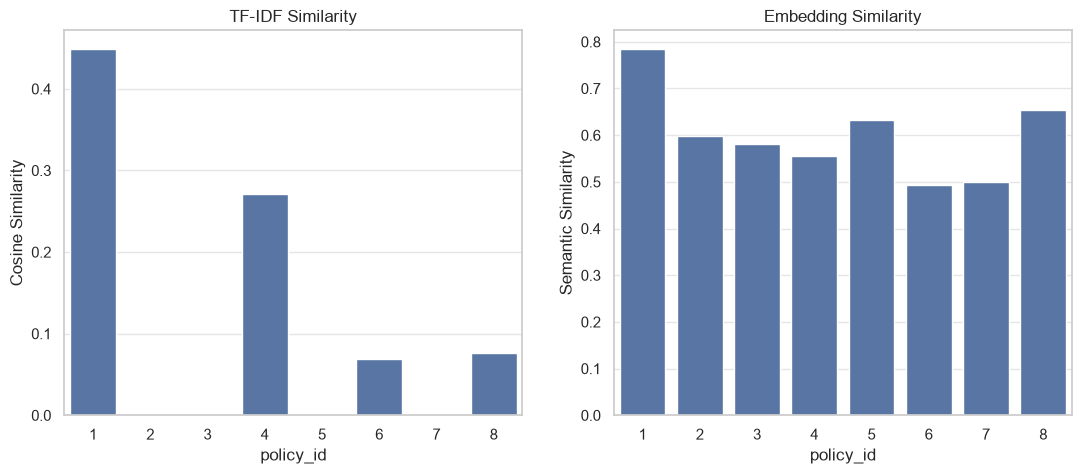

In [10]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(13, 5))

g0=sns.barplot(data=df, x="policy_id", y="tfidf_score", ax=axes[0])
g0.set_title("TF-IDF Similarity")
g0.set_ylabel("Cosine Similarity")

g1=sns.barplot(data=df, x="policy_id", y="embedding_score", ax=axes[1])
g1.set_title("Embedding Similarity")
g1.set_ylabel("Semantic Similarity")

## Evaluate retrieval quality

Similarity scores alone cannot tell us whether a retrieved policy is actually relevant to our research question.

We need human relevance judgments.

For this example, we'll manually label policies 1, 2, and 5 as relevant to wildfire-related waste management.

In [11]:
# Human-assigned relevance labels
df["relevant"] = df["policy_id"].isin([1, 2, 5]).astype(int)

# Retrieve the top 3 policies from each method
top3_tfidf = df.nlargest(3, "tfidf_score")
top3_embedding = df.nlargest(3, "embedding_score")

# Calculate Precision@3
precision_tfidf = top3_tfidf["relevant"].mean()
precision_embedding = top3_embedding["relevant"].mean()

print(f"TF-IDF Precision@3: {precision_tfidf:.2f}")
print(f"Embedding Precision@3: {precision_embedding:.2f}")

TF-IDF Precision@3: 0.33
Embedding Precision@3: 0.67
